# Tutorial 2: Modeling Astrochemical Reactions on Dust Grains
_Marco Cappelletti, Dario Campisi, Luuk Kempen, Mie Andersen_



<hr>

Before you begin this tutorial, run the cell below by hovering over it and
clicking the "play" icon to set up the Python environment for this tutorial.

In [ ]:
try:
    import ics26
except ImportError:
    !uv pip install --compile-bytecode "ics26[modeling] @ git+https://github.com/lkkmpn/intercat-school-2026.git"

from ics26.modeling import setup_notebook

setup_notebook()

<hr>

In this tutorial, we see how computational chemistry can be used to model
astrochemical reactions. We will calculate the barrier of a simple reaction
and hence estimate how it may proceed in the interstellar medium.

To compute the energies, we will use the machine learning potential
**MACE-OMOL** (from now on, simply MACE), which is trained on costly density
functional theory calculations and represents a cheap yet reliable method.
The OMol25 dataset contains millions of DFT calculations (at the
ωB97M-V/def2-TZVPD level) on molecules, but also charged and radical species.

We will use the Atomic Simulation Environment (**ASE**) Python package to define
our system and perform all calculations.

## Background

Dense molecular clouds are environments with a rich chemistry. Due to the low
temperatures ($10\mathrm{-}20\,\mathrm{K}$) that hinder gas-phase reactions,
surface-catalyzed reactions on dust grains play a major role and enable complex
chemical pathways.

As the direct observation of such reactions is a major experimental challenge,
computational chemistry represents an essential tool for astrochemistry. With
it, one can compute individual reactions and estimate reaction energies and 
barriers, which help refine astrochemical models.

However, computational chemistry is not free from challenges. The most
important one is the accuracy-cost trade-off: in general, the more accurate you
want a calculation, the more computational resources you need. Although the
advent of machine learning (ML) drastically reduced such a cost, the
computational bottleneck still remains the major limitation for modeling medium
to large-sized chemical systems (the meaning of medium and large depends on the
method).

In this tutorial, benzene ($\mathrm{C}_6\mathrm{H}_6$) serves as our simplified
model for a carbonaceous dust grain surface. We will model the chemisorption of
a single hydrogen atom onto this carbon surface to understand a typical
astrochemical process.

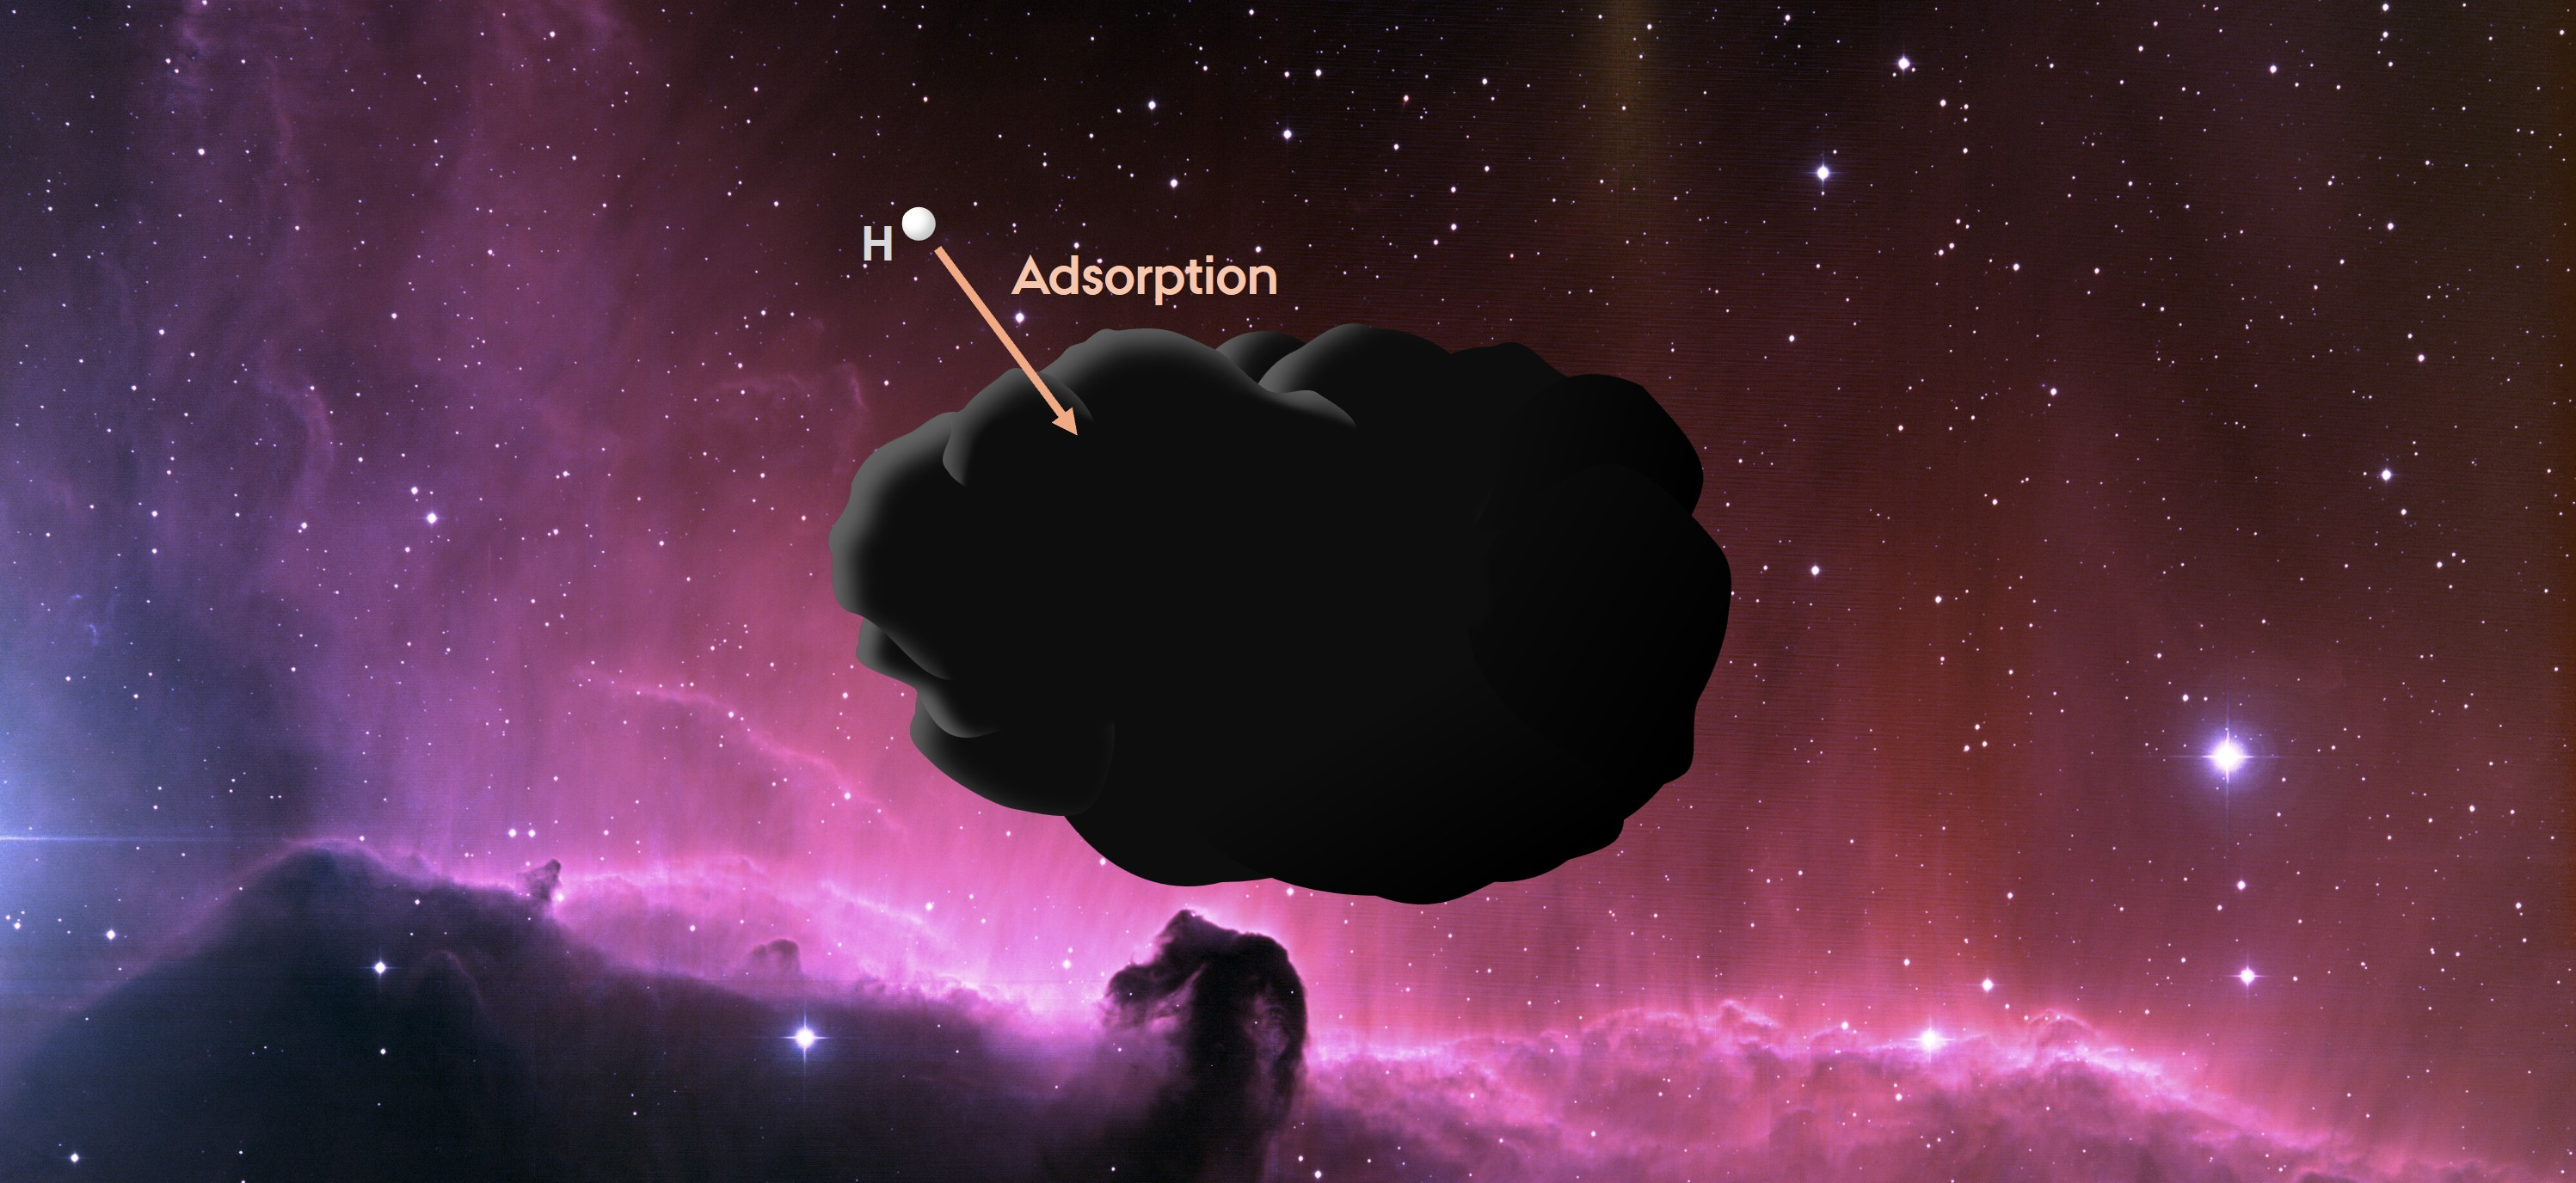

<hr>

## Preparation

The cell below will download the MACE potential; this might take a few minutes.
You will likely see some warnings, but you can ignore those.

In [ ]:
from mace.calculators import mace_omol

raw_model = mace_omol(model="extra_large", return_raw_model=True)

<hr>

## The reactants

To model a carbonaceous dust grain, we will use a single benzene ring, which
represents a reactive site of the grain surface.

Let's prepare our reactants (digitally)!

### Benzene

We start by defining our benzene molecule, using ASE.

In ASE, the `Atoms` object represents a chemical system, and carries
information about the structure, charge, spin, etc.

With the following commands, we ask ASE to search in PubChem for the structure
of benzene, and convert it into an `Atoms` object.

In [ ]:
from ase.data.pubchem import pubchem_atoms_search

benzene = pubchem_atoms_search(name='benzene')

print(f'Chemical formula: {benzene.symbols}')

This `Atoms` object is basically a fancy list, storing the element and position
for each atom:

In [ ]:
for i, atom in enumerate(benzene):
    print(f'Atom index {i:<2d} is element {atom.symbol} and is at position [{atom.position[0]:6.3f}, {atom.position[1]:6.3f}, {atom.position[2]:6.3f}]')

A quick visual inspection is good practice to verify that we have indeed loaded
the correct structure, and is easier to look at than the list of coordinates:

In [ ]:
from ase.visualize import view

view(benzene, viewer='x3d')

As shown above, each atom is referred to by an index (starting at 0).
We can also show the structure with the atoms labeled by their indices (you
will be using these later to refer to specific atoms):

In [ ]:
from ics26.modeling.plot import plot_atoms

plot_atoms(benzene, show_indices=True)

And we can check the bond distances and angles, using the indices we show above:

In [ ]:
print(f'C-C bond distance = {benzene.get_distance(0, 1):.3f} Å')
print(f'C-H bond distance = {benzene.get_distance(0, 6):.3f} Å\n')

print(f'C-C-C bond angle = {benzene.get_angle(0, 1, 3):.1f}°')

The benzene geometry that we extracted from PubChem is likely obtained from experimental data. However, while this represents an accurate estimation, it might not be the best geometry according to our potential, MACE. In other words, MACE may prefer different C-C and C-H bond distances.

Why?
Each method calculates energies and forces differently, and the equilibrium geometry may differ. This means that the true and the computed **potential energy surface (PES)** are often different.

Important: we cannot know *a priori* which is the PES of a given method, until you sample it thoroughly. The following image is just a figment of my imagination!

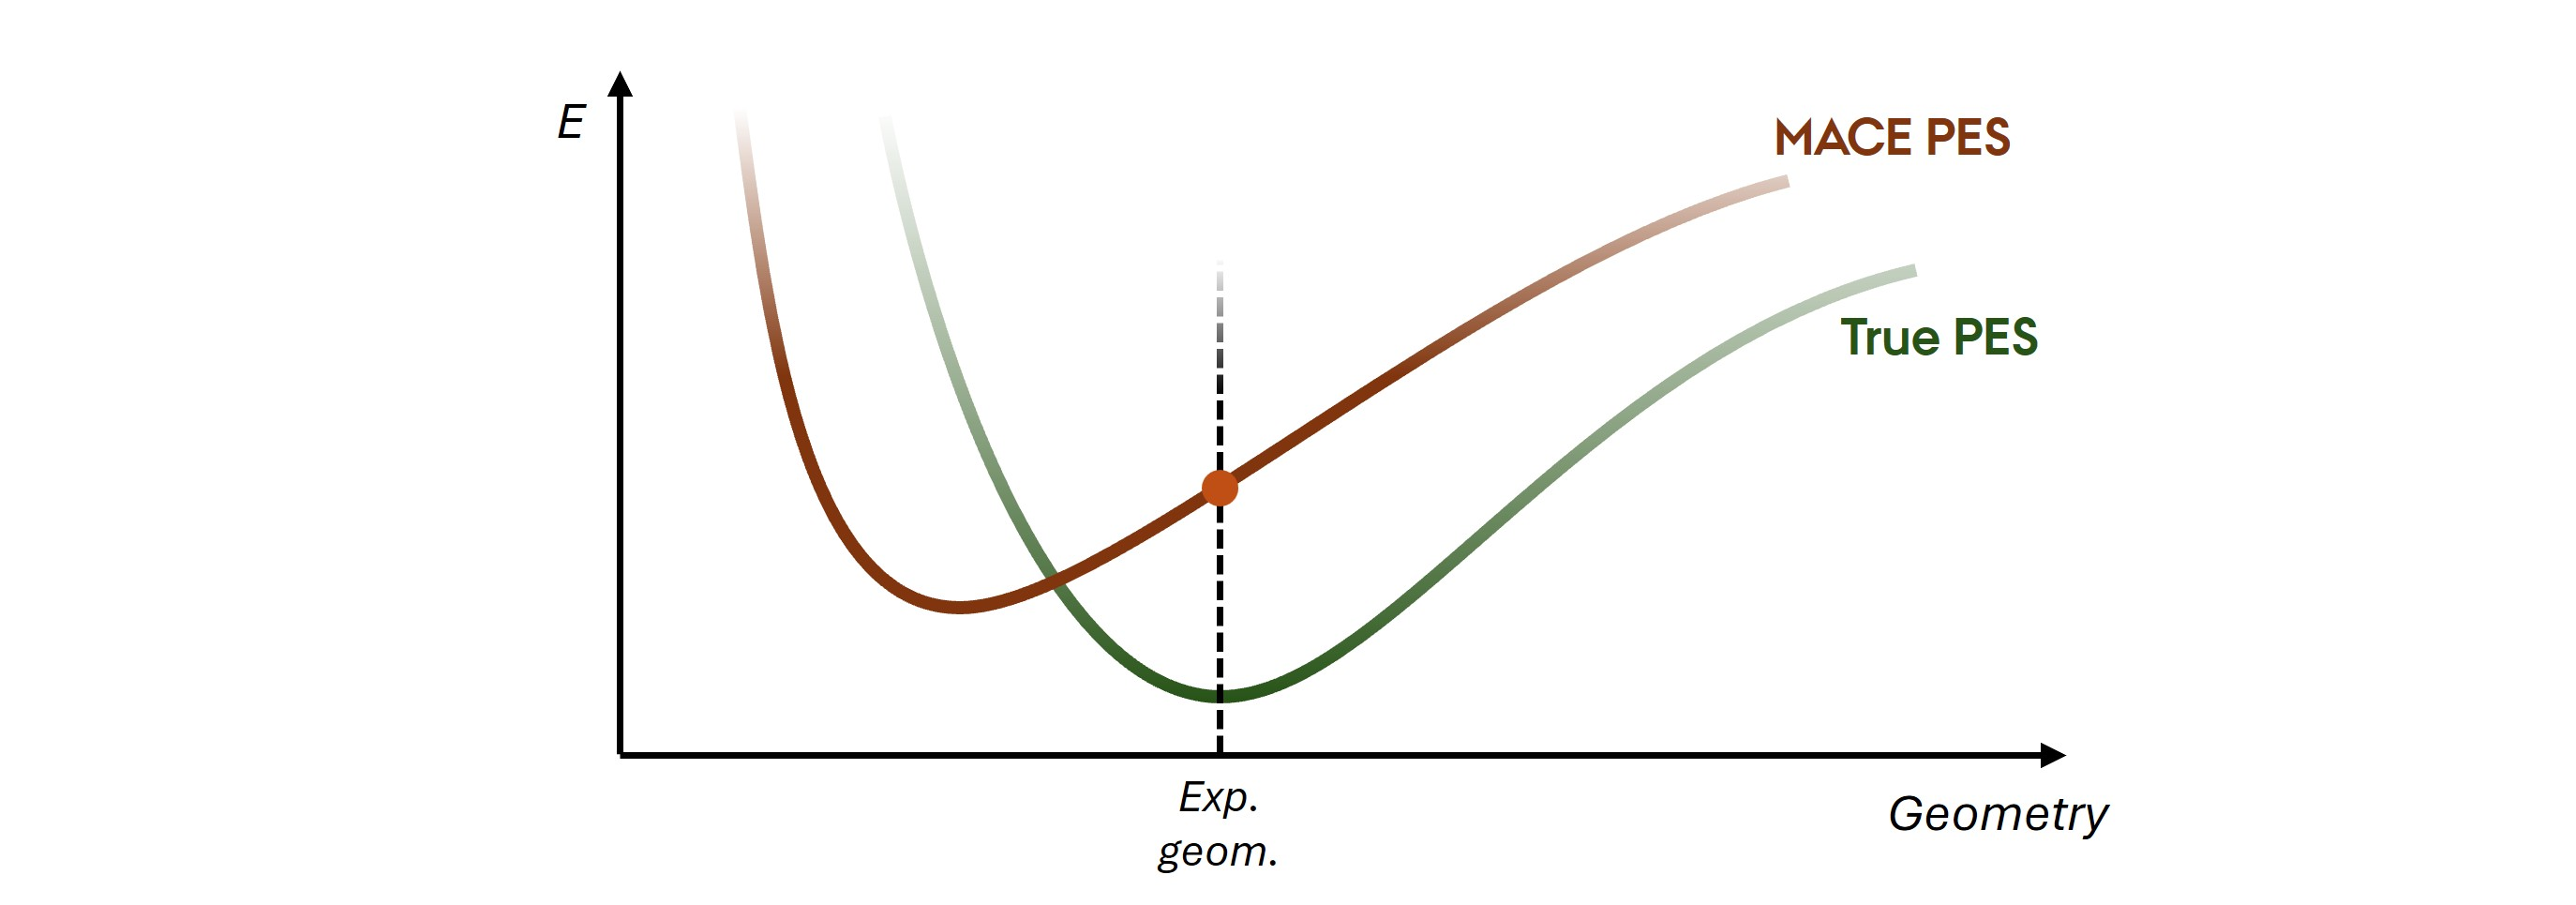

In computational chemistry we often need to work on geometries given by the
chosen level of theory, for many reasons. Thus, we need to perform a **geometry
optimization**. In this type of calculation, energy and forces acting on atoms
are computed, and the atoms are moved until the forces are zero (below a
certain threshold).

In mathematical terms, geometry optimization algorithms (e.g., LBFGS) typically
seek a local minimum in the PES, to obtain an equilibrium geometry. This search
is also called **relaxation**. Other algorithms seek a first-order saddle point
to obtain a transition state, which we will see later.

To perform the geometry optimization of our benzene, we first need to specify
its charge and multiplicity, and then tell ASE that we want to use MACE(-OMOL).

In [ ]:
from mace.calculators import MACECalculator

benzene.info['charge'] = 0.0
benzene.info['spin'] = 1.0

# ASE understands how to use the MACE model if we create this Calculator
mace_calc = MACECalculator(models=[raw_model], device='cpu')
benzene.calc = mace_calc  # attaches MACE calculator to the benzene Atoms object

We now tell ASE to use the LBFGS algorithm for the geometry optimization, and
run it. The `ImageRecorder` allows us to store the optimization steps.

In [ ]:
from ase.optimize.lbfgs import LBFGS
from ics26.utils import ImageRecorder

print('Performing geometry optimization of benzene...')

opt = LBFGS(atoms=benzene)
rec = ImageRecorder(benzene)
opt.attach(rec)
opt.run(fmax=0.01, steps=1000)

energy_benzene = benzene.get_potential_energy()

print(f'Done! Final energy: {energy_benzene:.2f} eV')

We now have the best benzene geometry according to our chosen method. Have a look at the optimization steps:

In [ ]:
from ics26.modeling.plot import plot_atoms_slider

plot_atoms_slider(rec.images)

And we can also see how bond distances and energy changed during the optimization:

In [ ]:
print(f'Step\td(C-C)\td(C-H)\tΔE (meV)')
for idx, step in enumerate(rec.images):
  print(f'   {idx}\t {step.get_distance(0, 1):.3f}\t {step.get_distance(0, 6):.3f}\t   {1000*(step.get_potential_energy()-energy_benzene):.3f}')

This means that, in the MACE potential, the experimental geometry is 8.6 meV (0.2 kcal/mol) higher than its predicted equilibrium geometry.

We can picture this schematically:

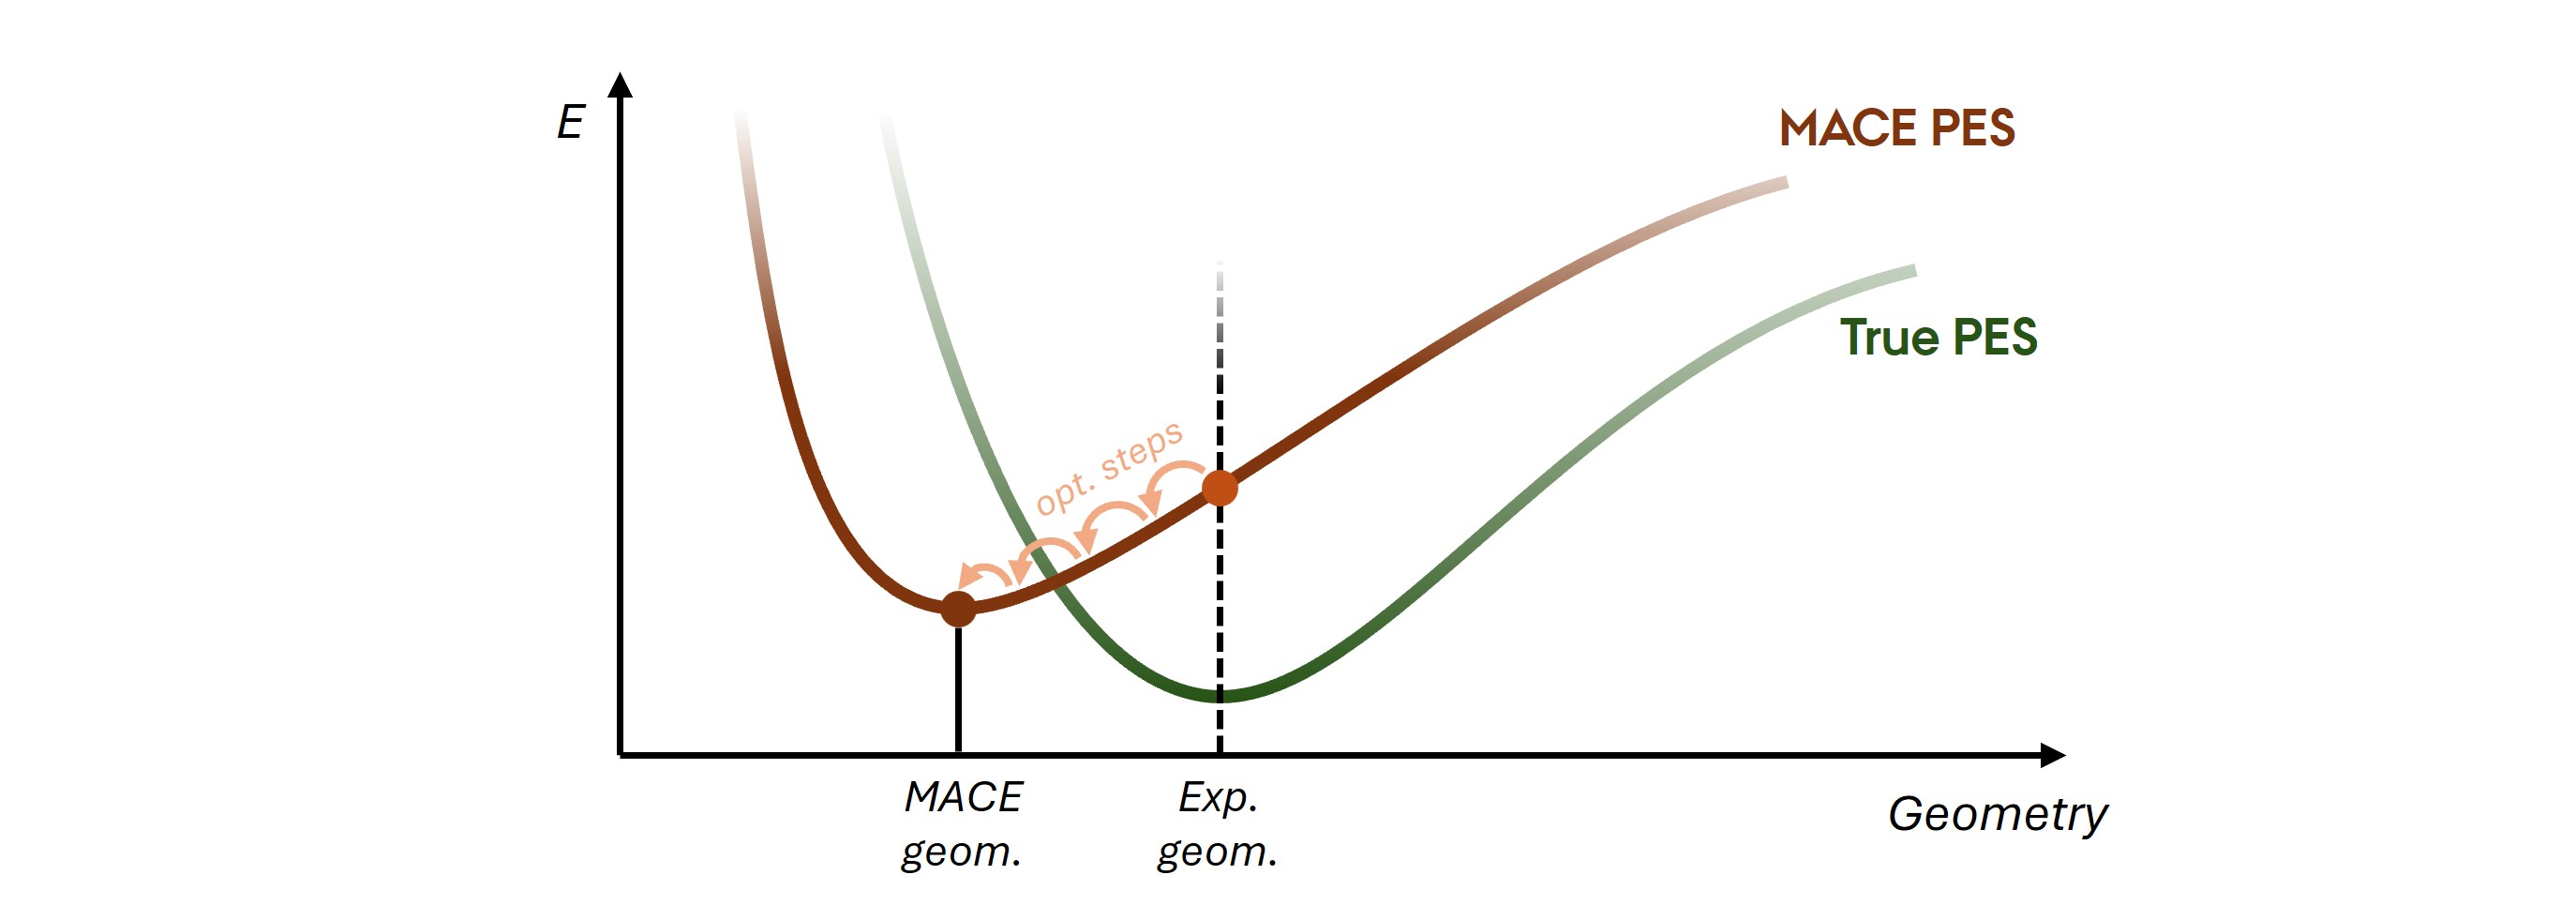

A small remark on energies: In computational chemistry, the energy of a chemical system is (related to) the energy that is released by bringing all nuclei and electrons together from infinite distance. This is why absolute energies are huge:

In [ ]:
print(f'Benzene energy (MACE): {energy_benzene:.2f} eV')

As you may notice, the energy of benzene is orders of magnitude larger than those involved in reactions and intermolecular interactions ($\sim$ 0.1 eV).

Charles Coulson once wrote that computing relative energies using
ground state energies is analogous to "determine the weight of the captain of a large ship by weighing the ship when he is and when he is not on board."

Therefore, computational chemistry methods must be extremely precise!

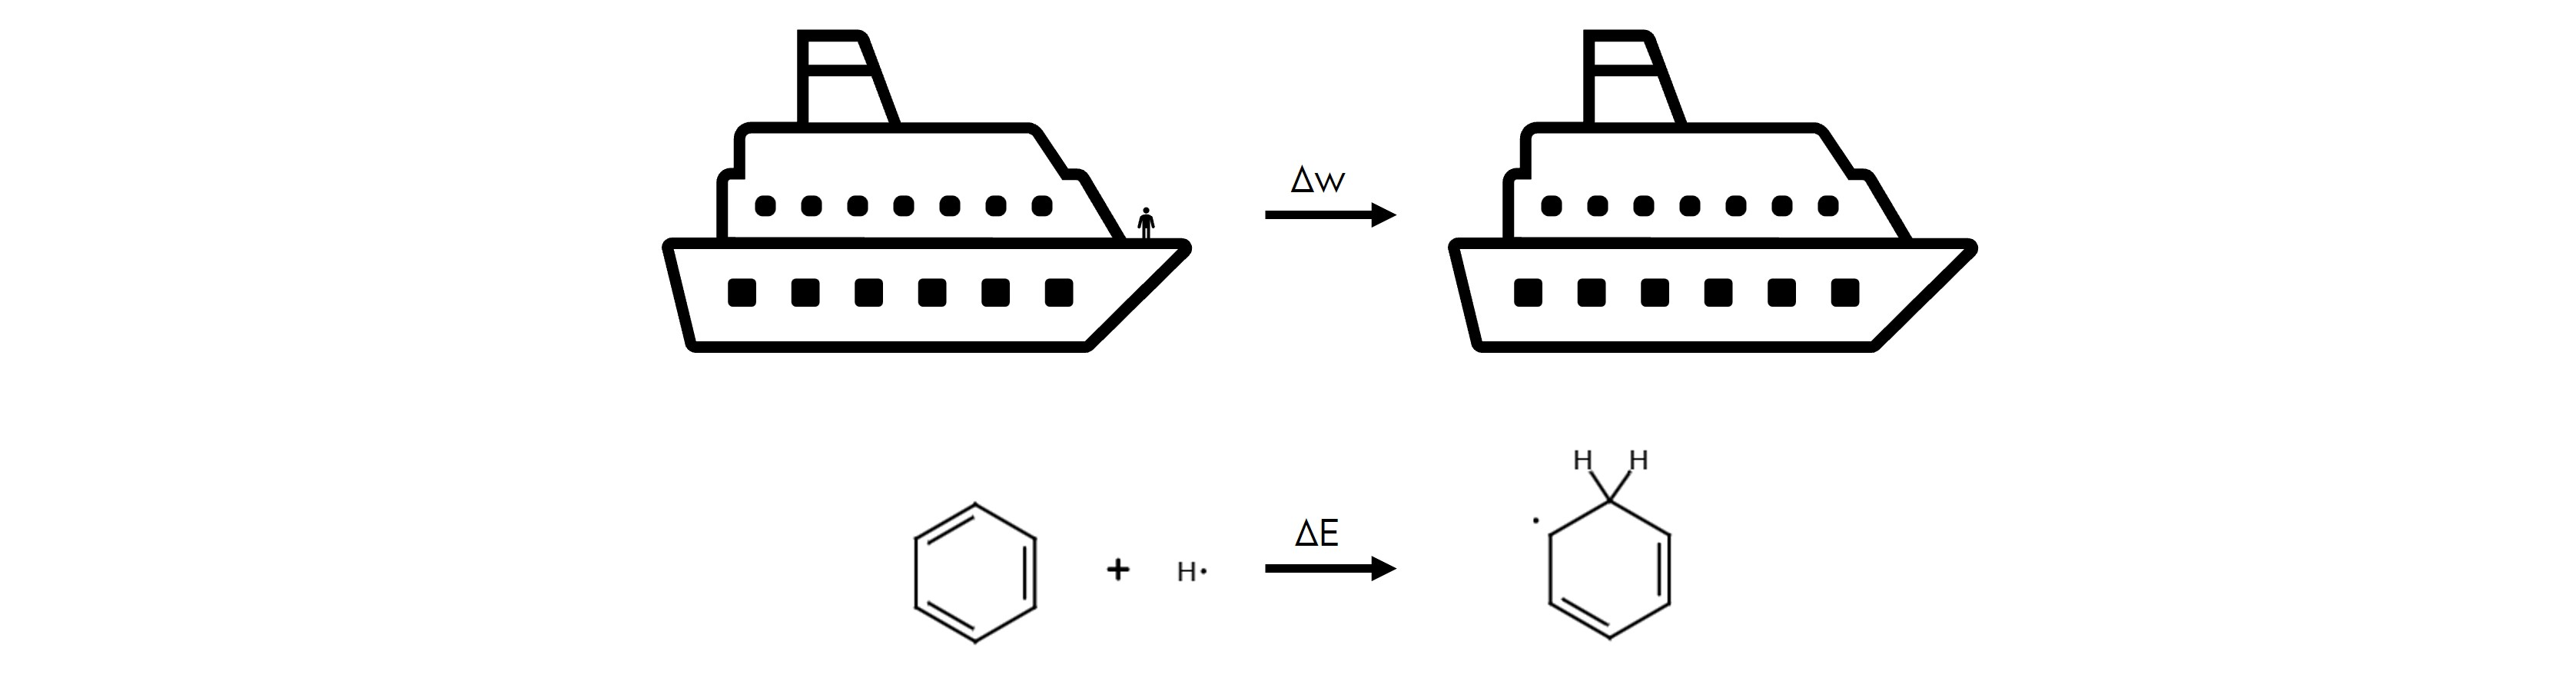

<hr>

### The hydrogen atom

To calculate the energy of the isolated reactants, we also need the energy of
the hydrogen atom.

<hr>

**Exercise 1:** The script needs your help! What is the multiplicity of an
isolated hydrogen atom? In `ASE`, the `Atoms` object has the property `spin`,
which is the spin multiplicity of the system. The multiplicity of an electronic
system is given by the formula $2S+1$, where $S$ is the total spin angular
momentum.

After specifying the correct value, run the cell to calculate the electronic
energy of the $\mathrm{H}$ atom.

In [ ]:
from ase.atoms import Atoms

hydrogen = Atoms('H')

hydrogen.info["charge"] = 0.0
hydrogen.info["spin"] = ...  # YOUR CODE HERE

# Run it with MACE again
hydrogen.calc = mace_calc
energy_H = hydrogen.get_potential_energy()
print(f'Hydrogen energy (MACE): {energy_H:.2f} eV')

**Verify:** in quantum mechanics, the hydrogen atom is a well-known solved system, with ground state energy:

$$
\begin{equation}
E = -\dfrac{m_e e^4}{8 \epsilon_0^2 h^2}
\end{equation}
$$

Calculate it using the script below and compare it with the MACE estimation.

💡 **Note:** in Python, exponentials are written as: $a^b \rightarrow$ `a**b`. Also, the times operator `*` is mandatory to include.


In [ ]:
m_e = 9.10938356e-31  # kg
e = 1.602176634e-19  # C
epsilon_0 = 8.8541878128e-12  # F/m
h = 6.62607015e-34  # J·s

E_qm_joules = ...  # YOUR CODE HERE

# Convert Joules to eV (1 eV = e Joules)
E_qm_eV = E_qm_joules / e
print(f"Ground-state hydrogen energy: {E_qm_eV:.2f} eV")

> Why didn't MACE return -13.61 eV?

<hr>

## The reaction

In order to react, a chemical system must typically overcome an energy barrier, called the **activation energy**. This barrier can be overcome by energy fluctuations due to thermal motion (thermal reactions), or following an energy input, such as light (photochemical reactions).

### Transition state search

The most probable transition path that a system follows during a reaction is the **minimum energy path (MEP)**. The highest point along a MEP is called **transition state (TS)**, which is a structure in between reactants and products. As mentioned, a TS is a first-order saddle point in the PES: it is a maximum along the reaction coordinate, and a minimum along all other coordinates.

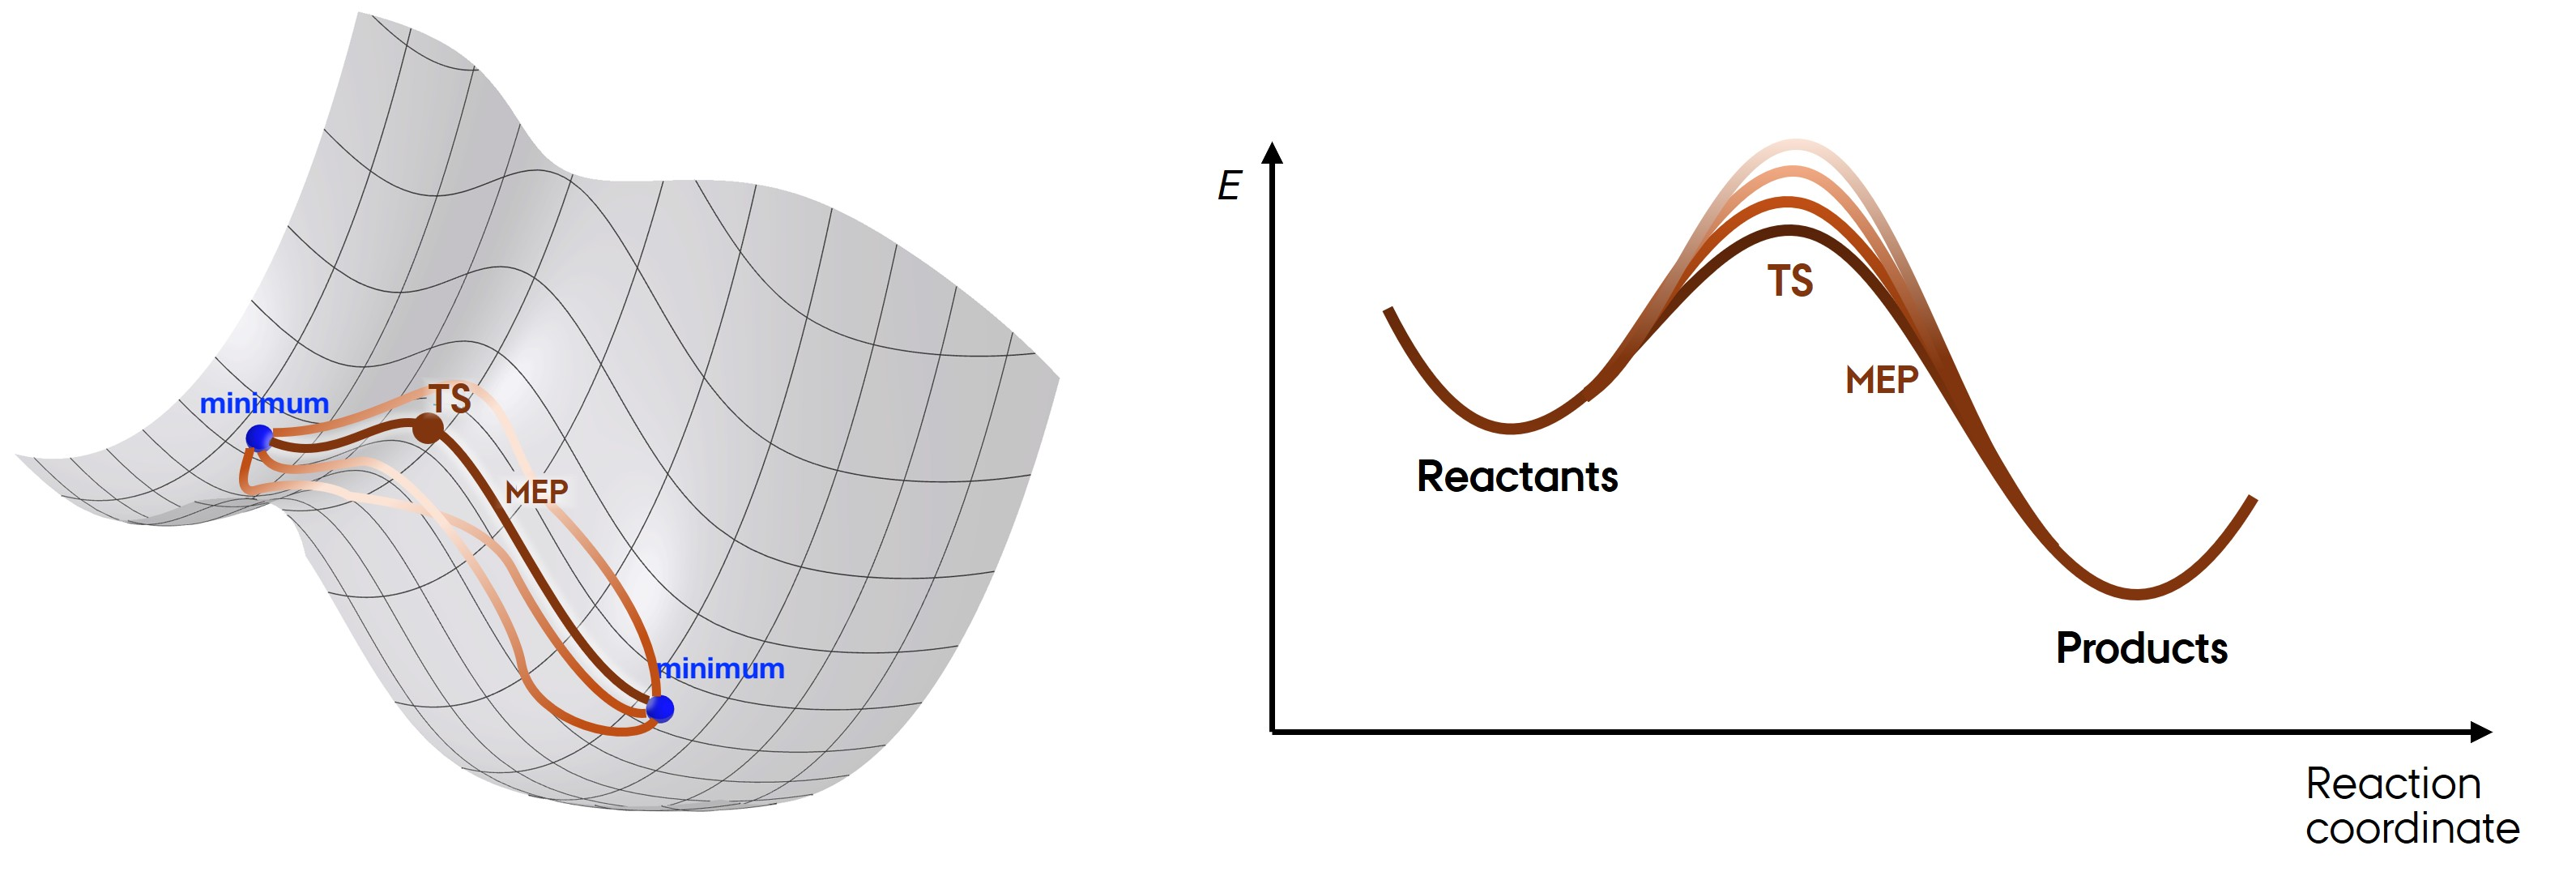

TS search is a challenging task in computational chemistry, because finding saddle points is not trivial like searching for a local minimum.

Tens (hundreds?) of different algorithms have been devised for efficient TS search. Here, we will use `Sella`. This algorithm takes a guess TS structure, and from there it jumps around on the PES to find the closest first-order saddle point.

We manually generate a guess by inserting a hydrogen atom at a reasonable distance from a carbon of our benzene (we choose the carbon atom indexed 3, but they are all equivalent by symmetry).

In [ ]:
# Get C3 position
C3_pos = benzene.positions[3]

# Create a displacement vector
disp_vec = [0.0, 0.4, 1.9]

# Define the position of the reacting H atom
H_pos = C3_pos + disp_vec

new_H = Atoms('H', positions=[H_pos])
ts = benzene + new_H

print(f'C3-H12 distance: {ts.get_distance(3, 12):.3f} Å')

view(ts, viewer='x3d')

We can now run Sella.

💡 **Note:** the first step might take a while, so don't worry if it is stuck
for a bit.

In [ ]:
from sella import Sella

ts.info['charge'] = 0.0
ts.info['spin'] = 2.0
ts.calc = mace_calc

sella = Sella(atoms=ts)
ts_rec = ImageRecorder(ts)
sella.attach(ts_rec)
sella.run(fmax=0.01, steps=1000)

energy_ts = ts.get_potential_energy()
print(f"\nTS energy (MACE): {energy_ts:.2f} eV")

Have a look at the final structure:

In [ ]:
view(ts, viewer='x3d')

And at the optimization steps, seen from the side:

In [ ]:
plot_atoms_slider(ts_rec.images, plane='zy-')

Schematic visualization of what we just did:

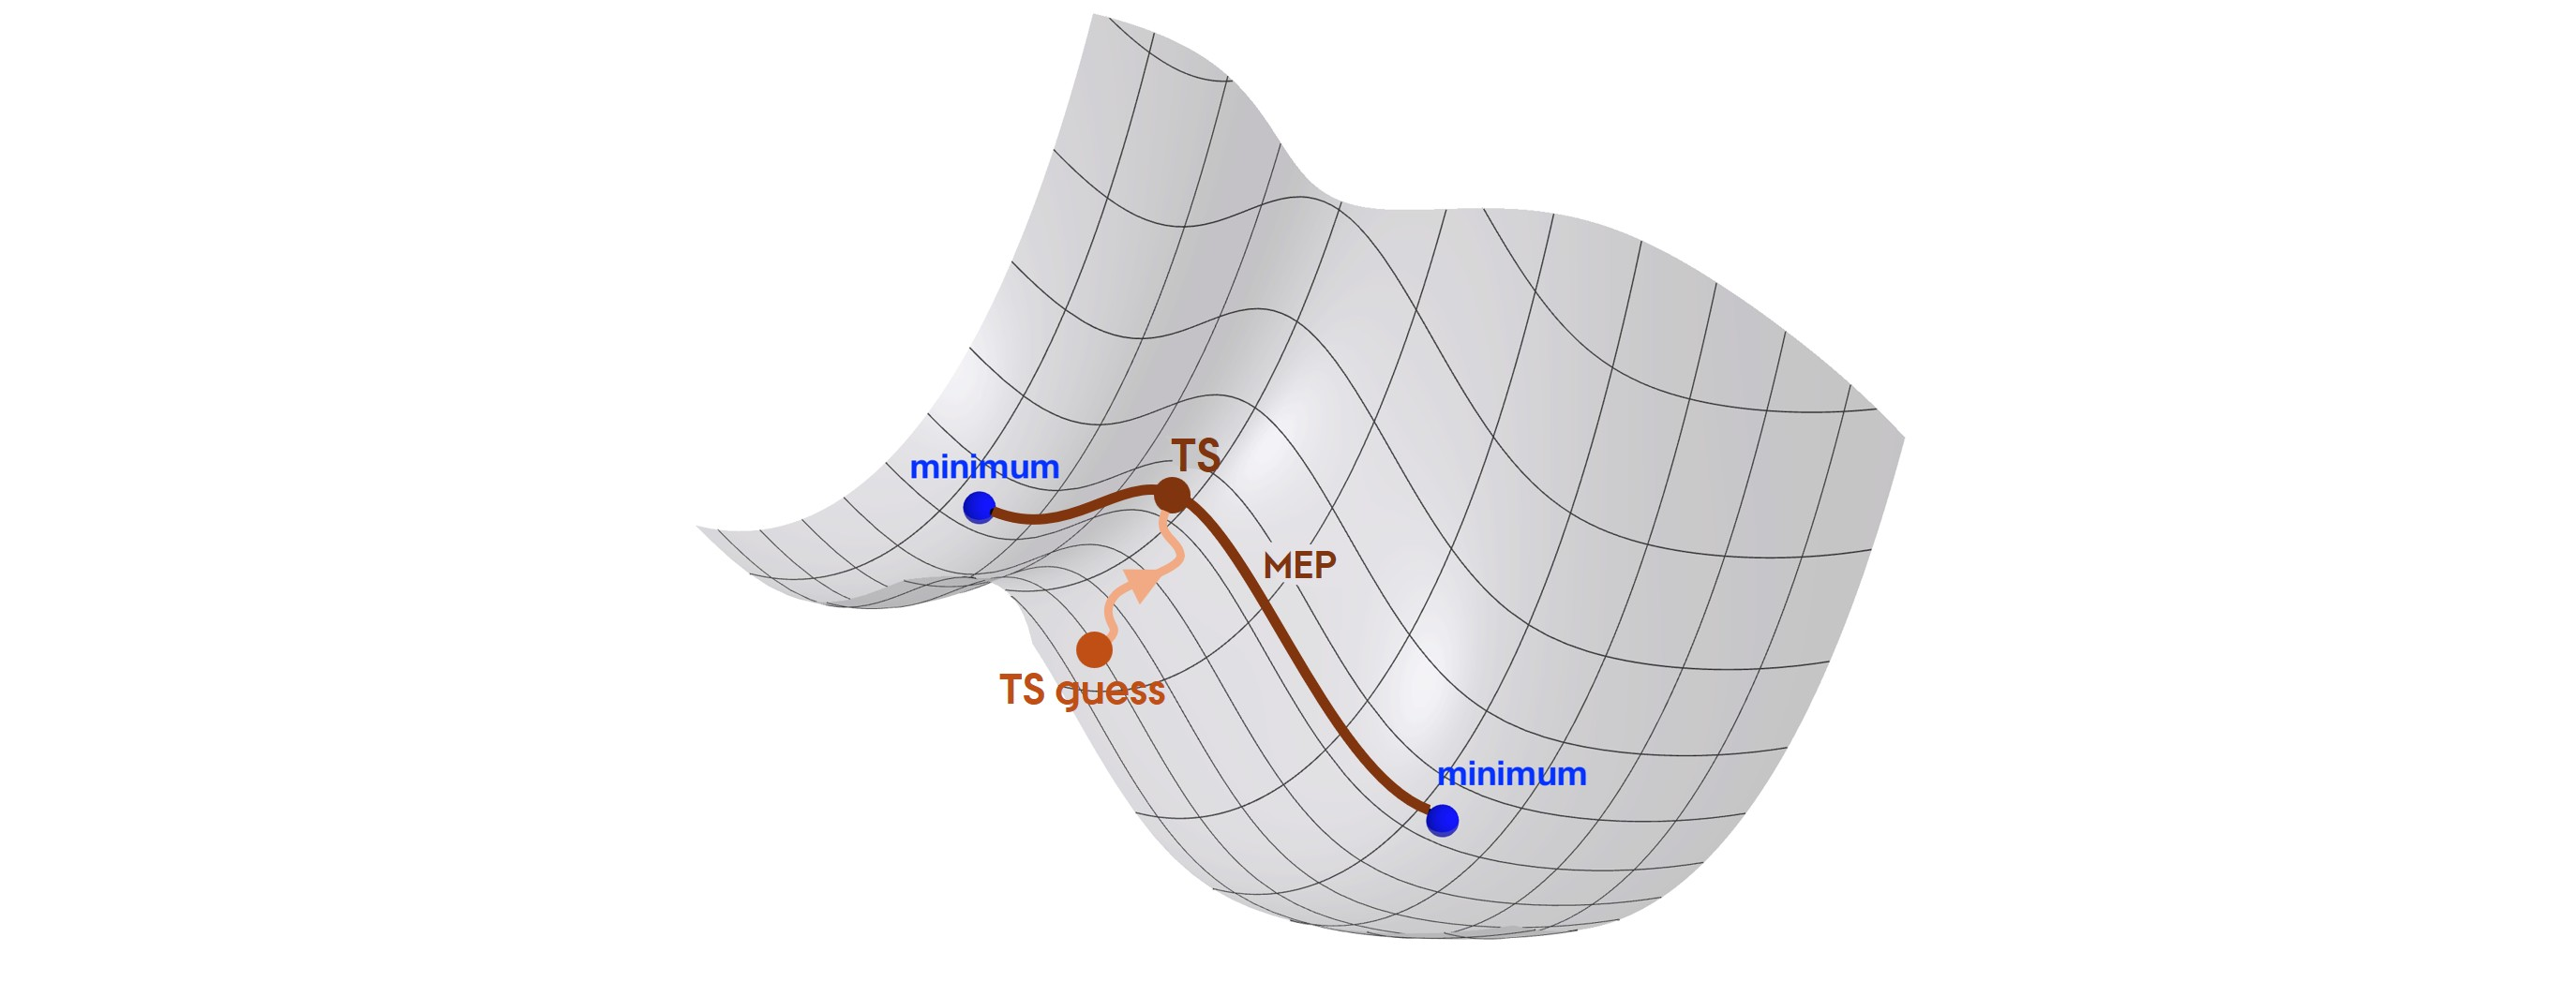

Of course, PESs are much more complicated than as shown in the picture above, and several TSs may exist close to each other. For this reason, it is crucial to create a guess that is as close as possible to your desired TS.

<hr>

**Optional exercise:** Play around with the `disp_vec` vector and see how the
TS search goes. Afterwards, make sure to return to the correct TS by running
Sella using our original guess with: `disp_vec = [0.0, 0.4, 1.9]`.

<hr>

### Vibrational analysis

To prove we actually found a TS, we need to calculate the vibrational frequencies of the structure.

As mentioned, a TS is a minimum in all coordinates except one, the reaction coordinate, where it is a maximum. The vibrational motion along the reaction coordinate is the movement that enables the reaction to occur.

The vibrational analysis is normally performed by means of the harmonic approximation. In this approach, the PES around a minimum is approximated by a quadratic potential.

$$ U = \frac{1}{2}kx^2 = \frac{1}{2}m\omega^2 x^2 $$

With $\omega$ the vibrational frequency (typically expressed in $\mathrm{cm}^{-1}$), which depends on the curvature of the PES at the minimum point.

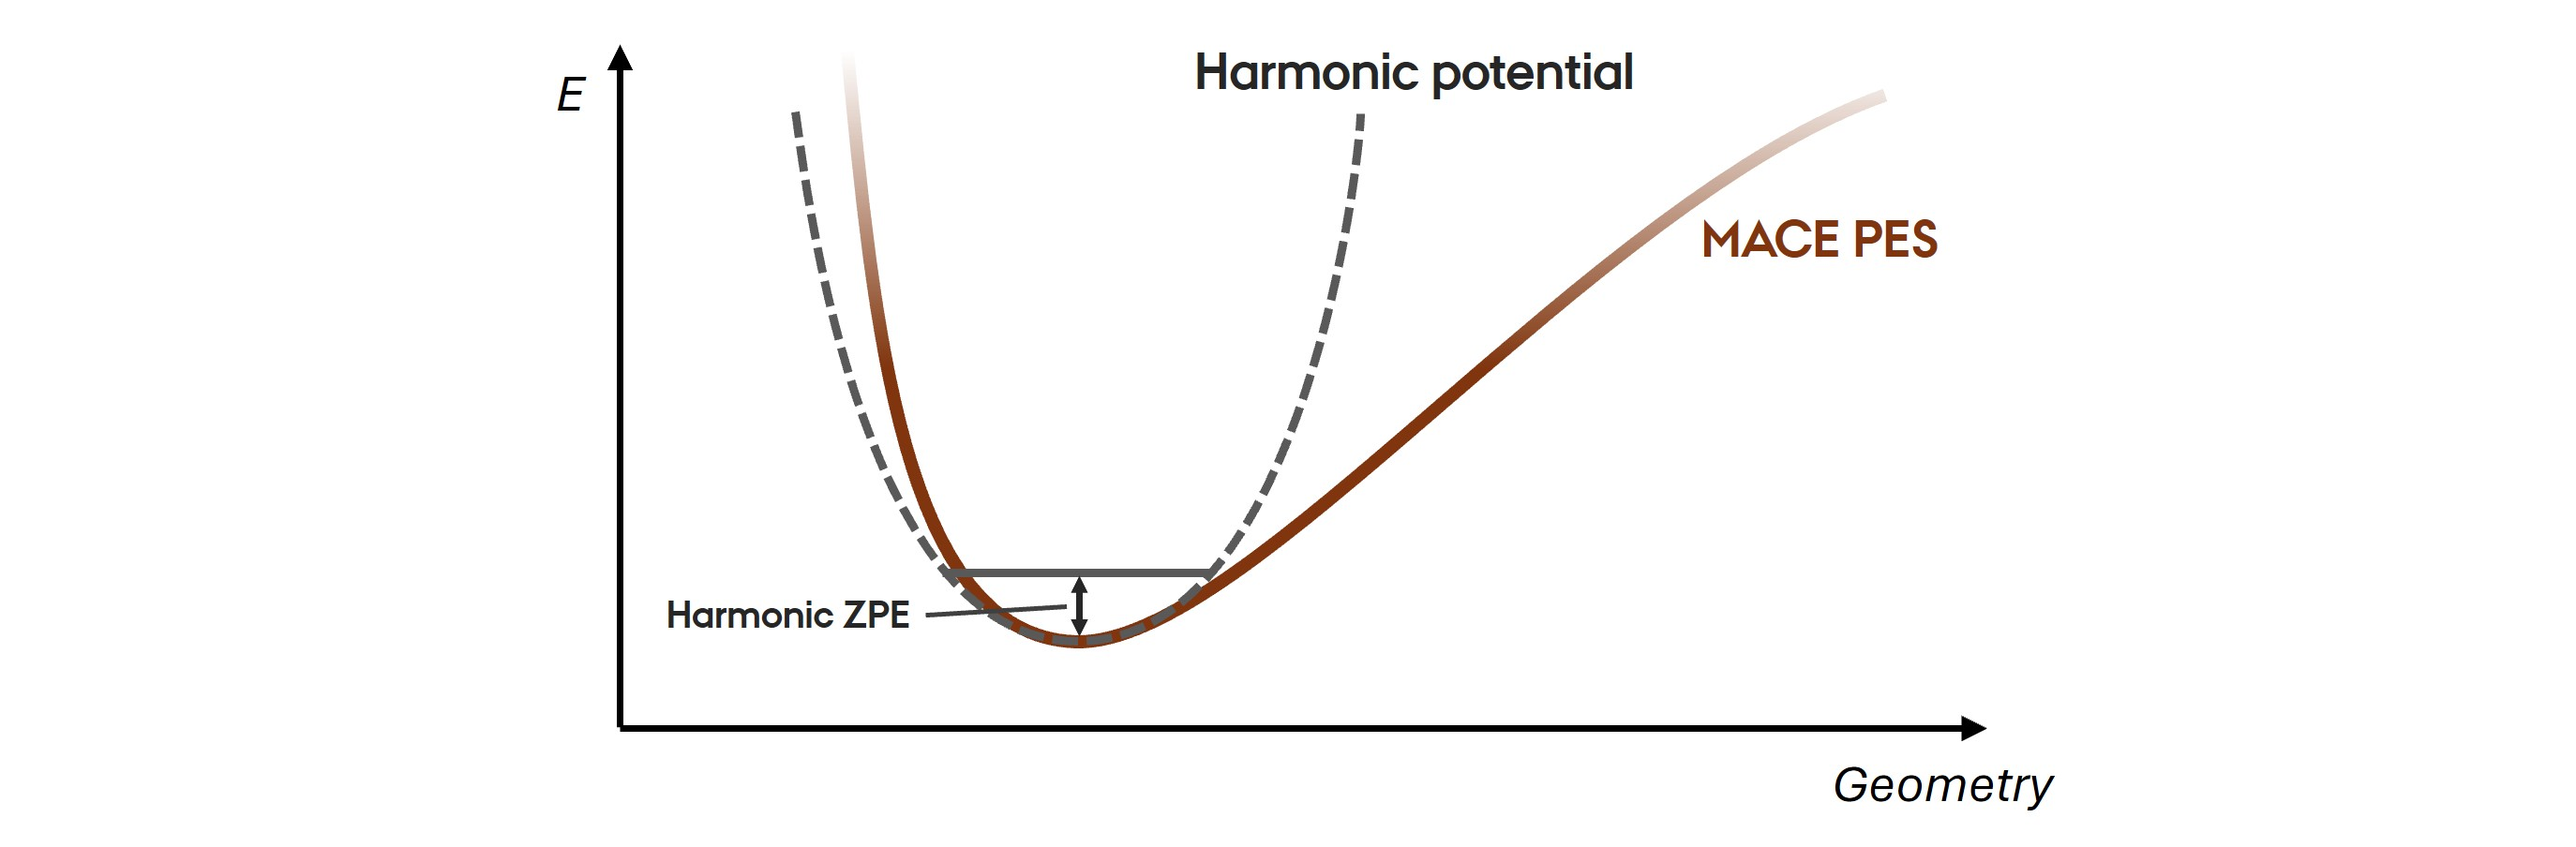

The harmonic potential at a maximum point is mathematically described by an **imaginary frequency** (why imaginary?).

Thus, in order to identify a TS, we need to obtain one (and only one) imaginary frequency, which tells us that we actually landed on a first-order saddle point. In our case, the vibrational motion associated to the imaginary frequency corresponds to the C3–H12 bond formation.

To save computational time, we will only calculate the vibrations for the three active atoms in the reaction, namely C3, H8, and H12. This is indicated by `indices=(3, 8, 12)`.

In [ ]:
from ase.vibrations import Vibrations

ts_vib = Vibrations(ts, name='ts_vib', indices=(3, 8, 12), delta=0.01)
ts_vib.run()
ts_vib.write_mode(0)  # save first vibrational mode to 'ts_vib.0.traj'
zpe_ts = ts_vib.get_zero_point_energy()
ts_vib.summary()

We can visualize this bond-formation vibrational motion:



In [ ]:
from ase.io import read

ts_imaginary_traj = read('ts_vib.0.traj', index=':')

plot_atoms_slider(ts_imaginary_traj, plane='zy-')

**Optional exercise:**

Use `ts_vib.write_mode(n)` and the code above to also visualize the other vibrational motions.

<hr>

## The product

To see whether the reaction is favorable or not, we need to compute the product.

We can use the trajectory file of the (imaginary) TS vibrational motion to generate a guess geometry of the product. We select structure number 8 from the trajectory, which is a (very) rough initial guess for product optimization.

In [ ]:
product = ts_imaginary_traj[7]  # image number 8

product.info['charge'] = 0.0
product.info['spin'] = 2.0

product.calc = mace_calc

print('Performing geometry optimization of the product...')

opt = LBFGS(atoms=product)
product_rec = ImageRecorder(product)
opt.attach(product_rec)
opt.run(fmax=0.01, steps=1000)

energy_product = product.get_potential_energy()
print(f'Done! Final energy: {energy_product:.2f} eV')

This optimization took a long time because our geometry guess was very far away
from the actual product minimum—it was close to the transition state, after all.
This is not the best practice in computational chemistry, especially because we
already know what the product geometry might look like. In a real scenario, we
could have waited for hours in vain! This is what we did:

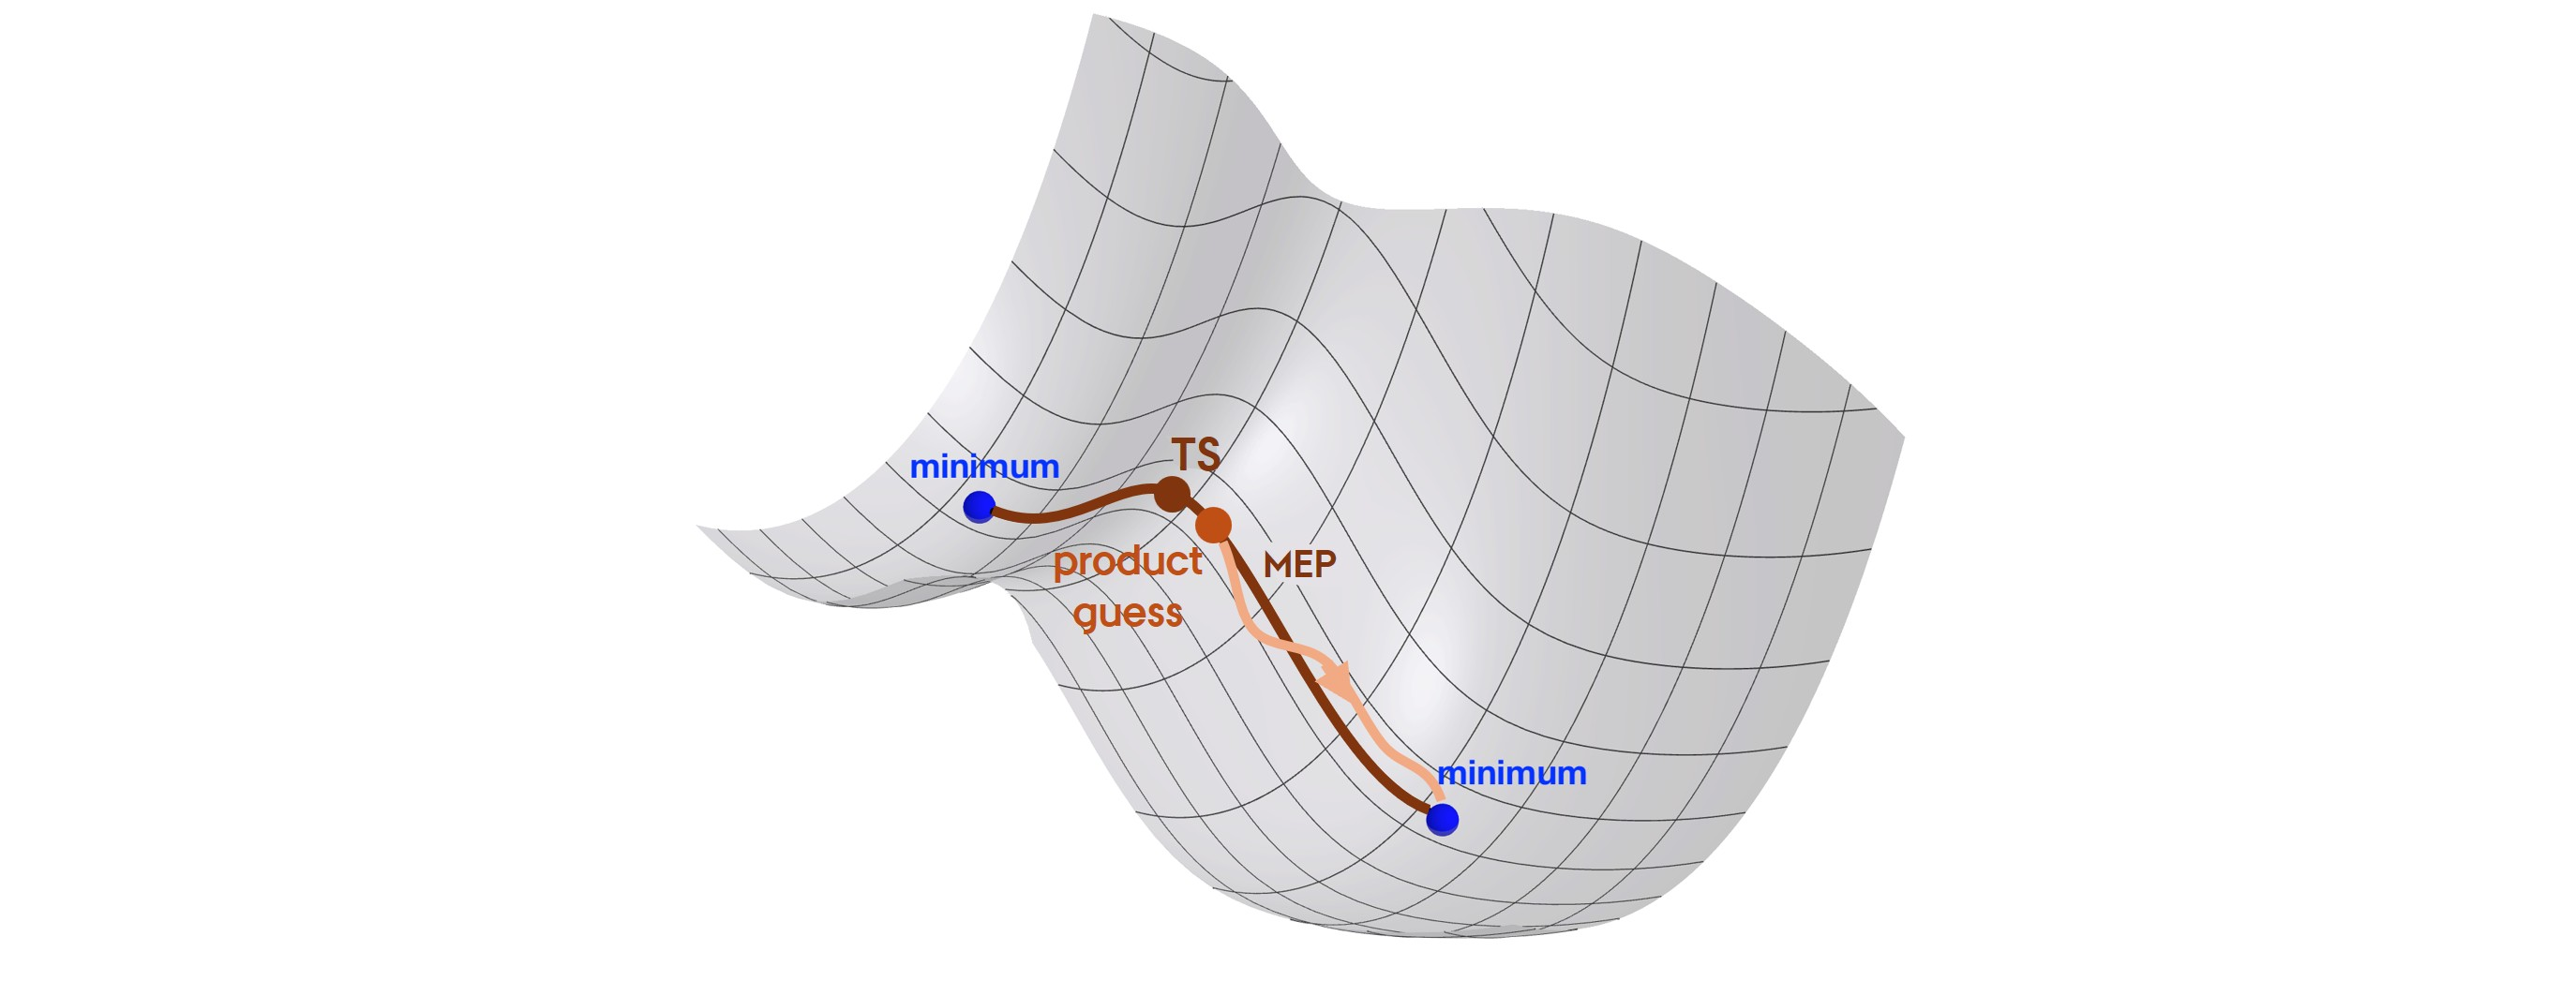

Have a look on the final geometry:

In [ ]:
view(product, viewer='x3d')

And the trajectory:

In [ ]:
plot_atoms_slider(product_rec.images, plane='zy-')

<hr>

## Binding energy and barrier

We are now ready to compute the binding energy of hydrogen sticking to the
surface, $E_{\mathrm{b}}$, and the barrier for this process, the activation
energy $E_{\mathrm{a}}$. But first, we need to include quantum effects.

### Zero-point energy

The zero-point energy (ZPE) is the lowest possible energy of a quantum mechanical system. The most common way used in computational chemistry to estimate the ZPE ($E_0$) is through the harmonic approximation (see figure in Vibrational analysis):

$$ E_{0} = \dfrac{1}{2}\hbar\omega $$

> The ZPE of the hydrogen atom is zero. **Why?**

Including ZPE corrections is necessary to obtain accurate reaction energies and barriers, because they (partly) account for quantum effects.

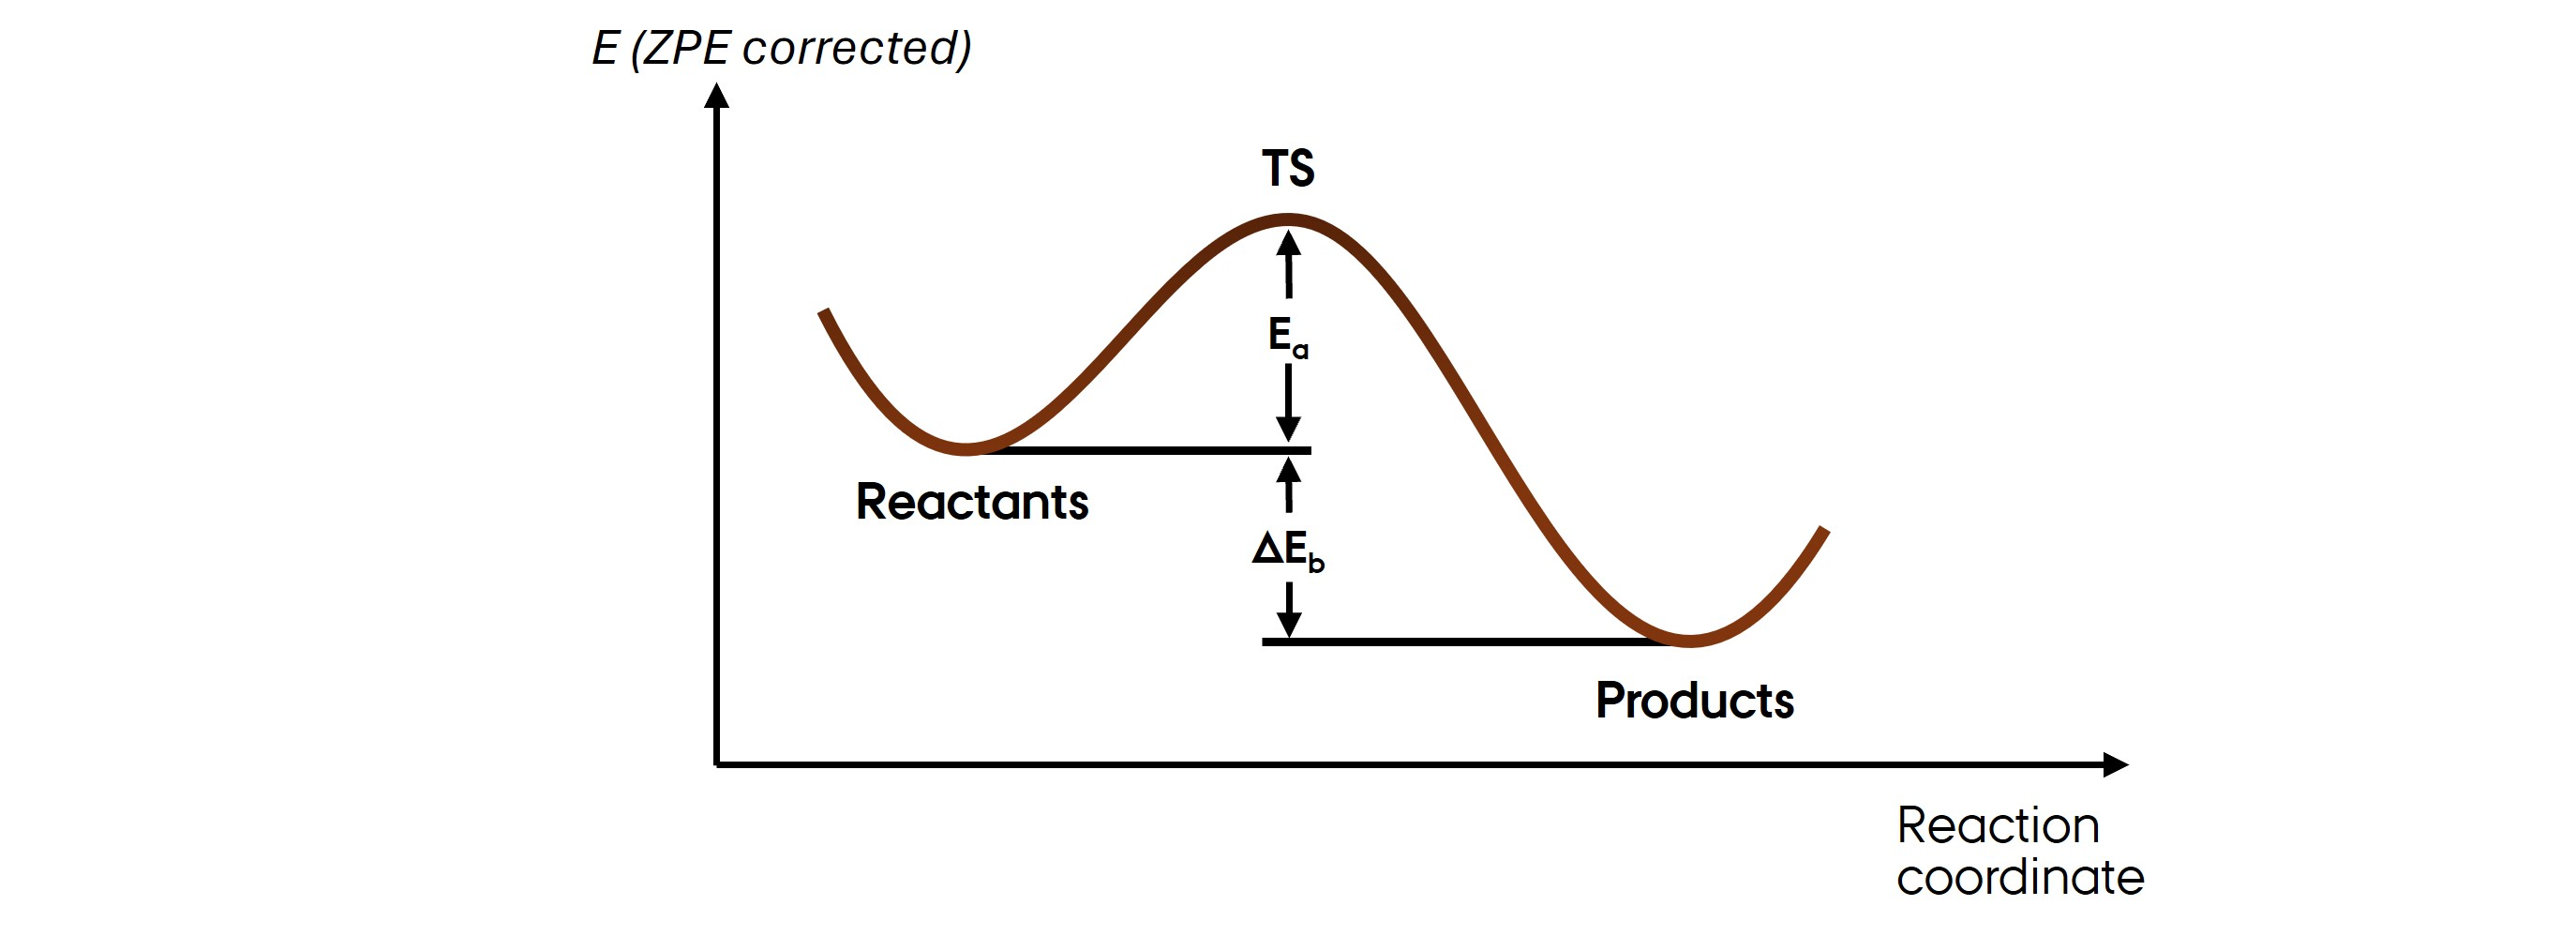

Let's perform the vibrational analysis on benzene:

In [ ]:
benzene_vib = Vibrations(benzene, name="benzene_vib", indices=(3, 8), delta=0.01)
benzene_vib.run()
zpe_benzene = benzene_vib.get_zero_point_energy()
benzene_vib.summary()

And on the product:

In [ ]:
product_vib = Vibrations(product, name="product_vib", indices=(3, 8, 12), delta=0.01)
product_vib.run()
zpe_product = product_vib.get_zero_point_energy()
product_vib.summary()

<hr>

### Final values

**Exercise 2:** Calculate the **binding energy** $E_{\mathrm{b}}$ (including ZPE corrections). Note: the binding energy is defined as a **positive value**. For a cleaner solution, use the variables we already defined, instead of inserting the raw numbers.

In [ ]:
energy_binding = ...  # YOUR CODE HERE
print(f'The binding energy is {energy_binding:.2f} eV')

<hr>

**Exercise 3:** Calculate the **activation energy** $E_{\mathrm{a}}$ (including
ZPE corrections). Same as above.

In [ ]:
energy_activation = ...  # YOUR CODE HERE
print(f'The activation energy is {energy_activation:.2f} eV')

<hr>

Let's create an unquestionably beautiful plot of the reaction:

In [ ]:
from chemdiagrams import EnergyDiagram

dia = EnergyDiagram()
dia.draw_path(x_data=[0, 1.5, 3], y_data=[0, energy_activation, -energy_binding], color='black')
dia.add_numbers_auto(n_decimals=2)
dia.set_xlabels(['Reactants', 'TS', 'Product'], labelplaces=[0, 1.5, 3])
dia.ax.set_ylabel('Energy / eV')
dia.show()

<hr>

## Reaction kinetics

We have all the ingredients to calculate the reaction rate.

There are two ways to overcome a finite energy barrier:

1.   Classically, by climbing it and passing at the top, granted that the kinetic energy is sufficient.
2.   By means of **quantum tunneling**, passing *through* the barrier.

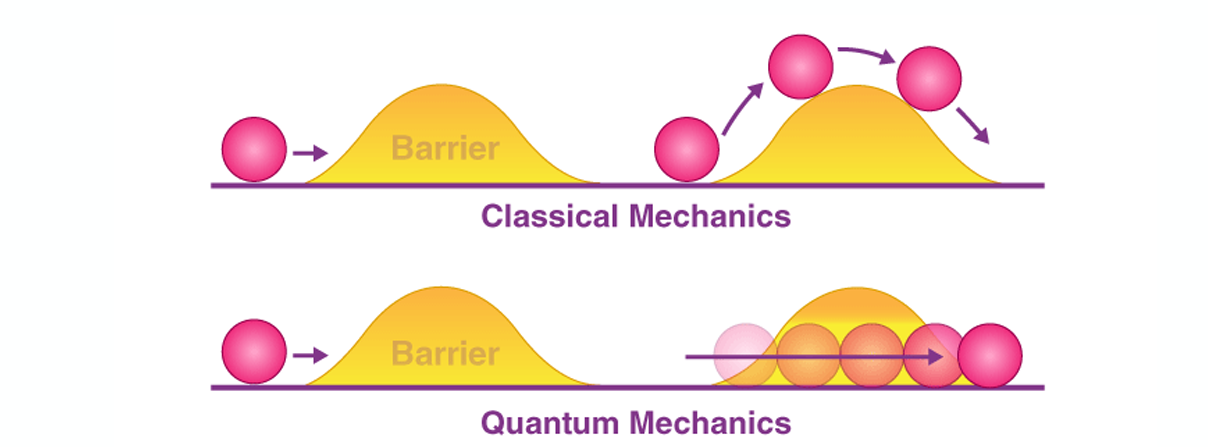

The **classical reaction rate** $k_{\mathrm{cl}}$ is given by the Arrhenius reaction

$$ k_{\mathrm{cl}} = A \exp \left( -\frac{E_{\mathrm{a}}}{k_{\mathrm{B}} T} \right), $$

With $A$ the pre-exponential factor, $E_{\mathrm{a}}$ the activation energy, $k_{\mathrm{B}}$ the Boltzmann constant, and $T$ the temperature.

This equation reflects the probability that the particles have sufficient thermal energy to overcome the $E_{\mathrm{a}}$ barrier for any given temperature. More precisely, the pre-exponential factor $A$ represents the frequency of two-particle collisions with the correct orientation for the reaction, whereas the exponential represents the fraction of particles with enough thermal energy.

In astrochemistry, we typically adopt the **Polanyi–Wigner model**, where the pre-exponential is approximated with the TS frequency $\nu$ (or rather its norm, as it is imaginary!):

$$ k_{\mathrm{cl}} \approx \nu \exp \left( -\frac{E_{\mathrm{a}}}{k_{\mathrm{B}} T} \right). $$

**Quantum tunneling** $k_{\mathrm{t}}$ is of course more complicated than colliding classical particles.

The tunneling rate decreases with the mass of a particle (in our case, a hydrogen atom, with mass $m_{\mathrm{H}}$), and it also depends on the shape of the barrier.

Here, we greatly simplify the system and we assume that the barrier is rectangular, with a width $W \approx 2.4\,\mathrm{Å}$. This brings to the tunneling correction:

$$ k_{\mathrm{t}} \approx \nu \exp \left( -2W \sqrt{2 m_{\mathrm{H}} (E_{\mathrm{a}} - k_{\mathrm{B}} T} ) / \hbar \right) $$

> Why do we only need the activation energy, and not the binding energy, to calculate the rates?

> How would you calculate the rate of the reverse reaction?

Here are the functions to calculate the rates:

In [ ]:
import numpy as np
from scipy.constants import hbar, k as kB_SI, e as eV_to_J

kB_eV = 8.61733e-5
C_CM_S = 2.99792e10
MASS_H = 1.673e-27
WIDTH_M = 2.379e-10

def tunneling_probability(barrier_eV, T_K):
    delta_E = np.maximum(barrier_eV * eV_to_J - kB_SI * T_K, 0.0)
    exponent = -2.0 * WIDTH_M * np.sqrt(2.0 * MASS_H * delta_E) / hbar
    return np.exp(exponent)

def classical_rate(T_K, barrier_eV, vib_cm1):
    nu = vib_cm1 * C_CM_S
    return nu * np.exp(-barrier_eV / (kB_eV * T_K))

def tunneling_rate(T_K, barrier_eV, vib_cm1):
    nu = vib_cm1 * C_CM_S
    return nu * tunneling_probability(barrier_eV, T_K)

Play around with the values to see how the reaction rates change:

In [ ]:
T = 200  # K
barrier = 0.21  # eV
vib_freq = 897.3  # cm-1

print(f'Classical rate: {classical_rate(T, barrier, vib_freq):.1e} s^-1')
print(f'Tunneling rate: {tunneling_rate(T, barrier, vib_freq):.1e} s^-1')

**Exercise 4:**

Observe how the rates change with temperature. For a given barrier and frequency, can you define the temperature range of a *classical regime* and a *quantum regime*? Can you explain why this happens?

<hr>

**Optional exercise:**

Before jumping to the next part, roughly sketch a plot of the classical and tunneling rates with temperature.

<hr>

Let's plot the rates of our reaction! In astrochemistry, we typically plot the logarithm of the rate vs the inverse of the temperature, so to linearize the Arrhenius equation.

Play around with the parameters to see how the crossover between the rates changes.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

barrier_height = energy_activation  # eV, you are free to change it
vib_freq = ...  # cm^-1, you are free to change it
T_min = ...  # K, you are free to change it
T_max = ...  # K, you are free to change it

temperatures = np.linspace(T_min, T_max, 100)

k_cl = classical_rate(temperatures, barrier_height, vib_freq)
k_t  = tunneling_rate(temperatures, barrier_height, vib_freq)

k_total = k_cl + k_t

fig, ax = plt.subplots(figsize=(5, 5))

ax.plot(1 / temperatures, np.log10(k_cl), label='Classical')
ax.plot(1 / temperatures, np.log10(k_t),  label='Tunneling')
ax.plot(1 / temperatures, np.log10(k_total), label='Total', linestyle='--', color='black', alpha=0.8)

inv_ticks = np.linspace(1 / T_max, 1 / T_min, 5)
ax.set_xticks(inv_ticks, [f'1/{round(1 / x)}' for x in inv_ticks])
ax.set_xlabel(r'1 / T (K$^{-1}$)')
ax.set_ylabel(r'$\log_{10}$(Rate / s$^{-1}$)')

ax.legend()

plt.show()

**Exercise 5:**

Which is the crossover temperature (where the two rates are the same) of our reaction?

**Exercise 6:**

How does the crossover temperature change with the barrier? Why?